c:\Users\Viktor\Documents\dipp\parking-prediction\.venv\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
c:\Users\Viktor\Documents\dipp\parking-prediction\.venv\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
c:\Users\Viktor\Documents\dipp\parking-prediction\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                     Parkings  day_of_year  weekday  hour  is_holiday
2021-10-11 00:10:00         1          284        1     0           0
2021-10-11 00:11:00         1          284        1     0           0
2021-10-11 00:12:00         1          284        1     0           0
2021-10-11 00:13:00         1          284        1     0           0
2021-10-11 00:14:00         1          284        1     0           0
...                       ...          ...      ...   ...         ...
2021-12-31 23:55:00        78          365        5    23           0
2021-12-31 23:56:00        78          365        5    23           0
2021-12-31 23:57:00        78          365        5    23           0
2021-12-31 23:58:00        78          365        5    23           0
2021-12-31 23:59:00        78          365        5    23           0

[118070 rows x 5 columns]
                     Parkings  day_of_year  weekday  hour  is_holiday
Time                                                           

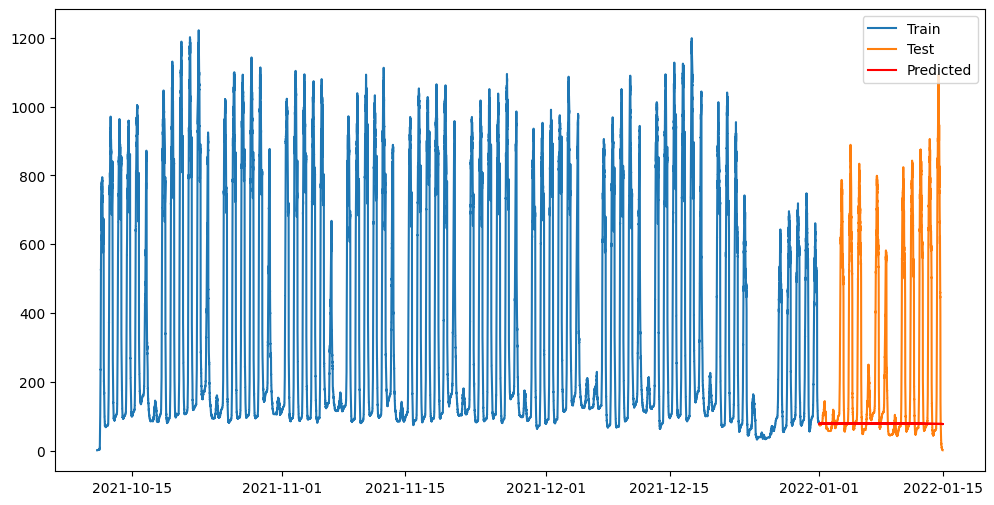

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from datetime import datetime

# Load the dataset
df = pd.read_csv('../preprocess/parking_time_series_with_features.csv', delimiter=',')

# Parse the 'Time' column to datetime and set it as index
df['Time'] = pd.to_datetime(df['Time'])
df.set_index('Time', inplace=True)
df.sort_index(inplace=True)

# Split the data into training and test sets
end_date = datetime(2022, 1, 1)
train_data = df[df.index < end_date]
test_data = df[df.index >= end_date]

# Ensure the training data index has a frequency set
train_data.index = pd.DatetimeIndex(train_data.index.values, freq=train_data.index.inferred_freq)

# Define SARIMA model parameters (p, d, q) and seasonal parameters (P, D, Q, m)
p = 3
d = 1
q = 2
P = 1
D = 1
Q = 1
m = 7  # Assuming weekly seasonality

# Fit the SARIMA model
model = SARIMAX(train_data['Parkings'], order=(p, d, q), seasonal_order=(P, D, Q, m))
sarima_results = model.fit()

# Predict using the fitted model
predictions = sarima_results.predict(start=test_data.index[0], end=test_data.index[-1], dynamic=False)

# Print the data and predictions
print(train_data)
print(test_data)
print(predictions)

# Plot the actual vs predicted values
plt.figure(figsize=(12, 6))
plt.plot(train_data.index, train_data['Parkings'], label='Train')
plt.plot(test_data.index, test_data['Parkings'], label='Test')
plt.plot(test_data.index, predictions, label='Predicted', color='red')
plt.legend()
plt.show()


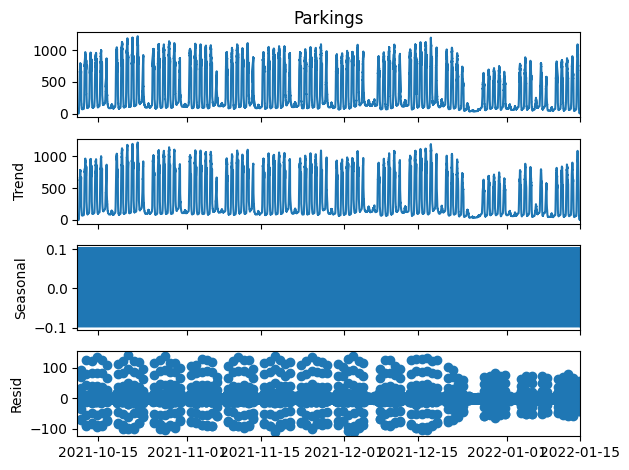

c:\Users\Viktor\Documents\dipp\parking-prediction\.venv\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
c:\Users\Viktor\Documents\dipp\parking-prediction\.venv\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
c:\Users\Viktor\Documents\dipp\parking-prediction\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


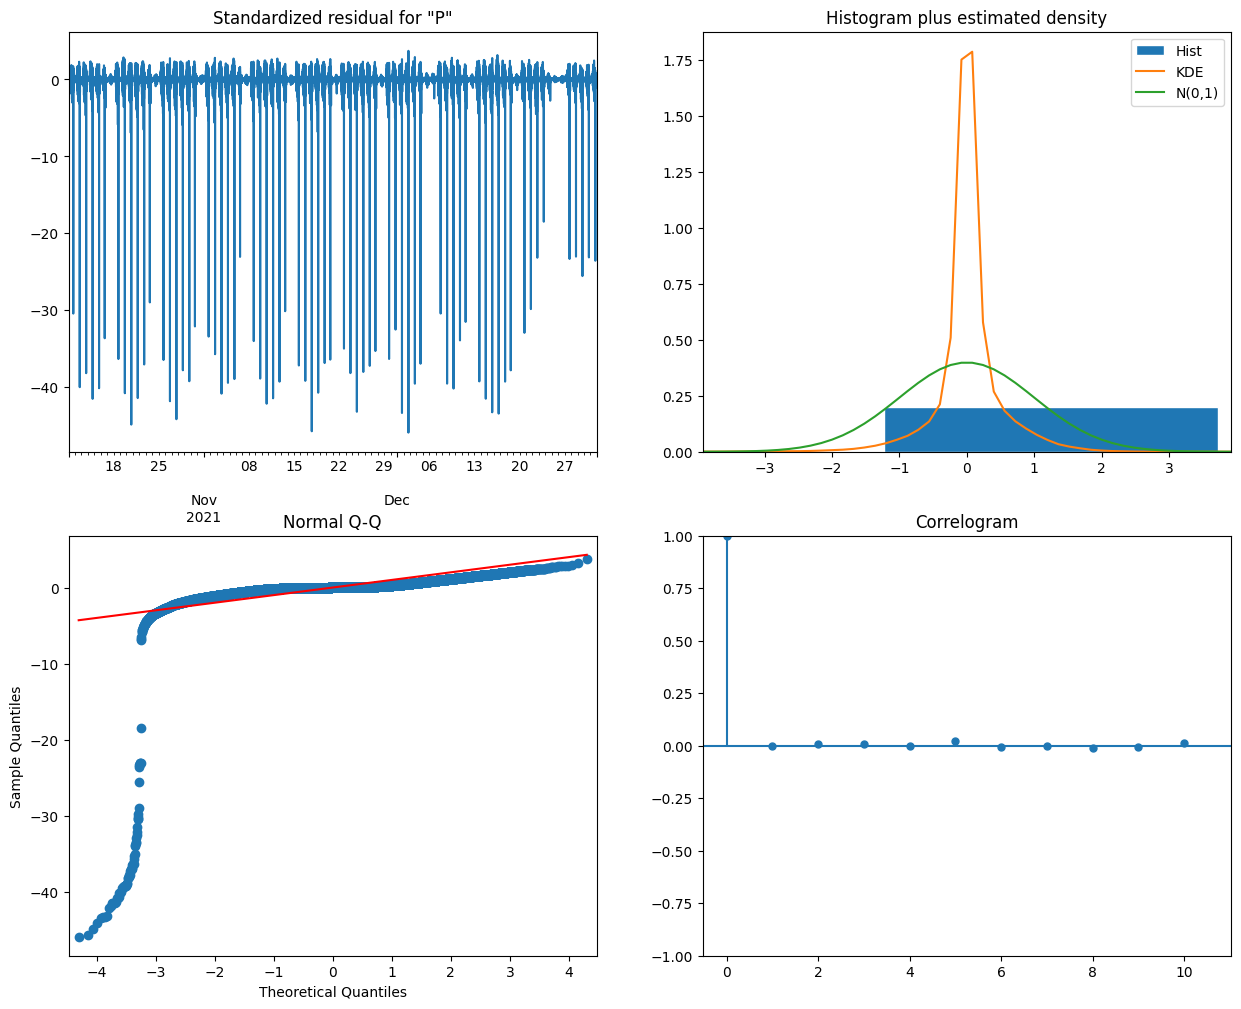

                     Parkings  day_of_year  weekday  hour  is_holiday
2021-10-11 00:10:00         1          284        1     0           0
2021-10-11 00:11:00         1          284        1     0           0
2021-10-11 00:12:00         1          284        1     0           0
2021-10-11 00:13:00         1          284        1     0           0
2021-10-11 00:14:00         1          284        1     0           0
...                       ...          ...      ...   ...         ...
2021-12-31 23:55:00        78          365        5    23           0
2021-12-31 23:56:00        78          365        5    23           0
2021-12-31 23:57:00        78          365        5    23           0
2021-12-31 23:58:00        78          365        5    23           0
2021-12-31 23:59:00        78          365        5    23           0

[118070 rows x 5 columns]
                     Parkings  day_of_year  weekday  hour  is_holiday
Time                                                           

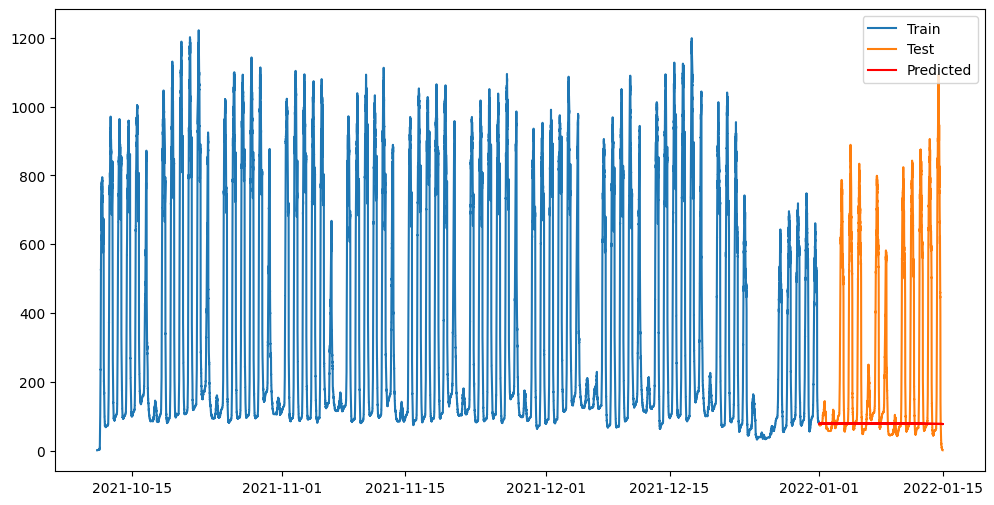

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.seasonal import seasonal_decompose
from datetime import datetime

# Load the dataset
df = pd.read_csv('../preprocess/parking_time_series_with_features.csv', delimiter=',')

# Parse the 'Time' column to datetime and set it as index
df['Time'] = pd.to_datetime(df['Time'])
df.set_index('Time', inplace=True)
df.sort_index(inplace=True)

# Seasonal decomposition to understand the components
decomposition = seasonal_decompose(df['Parkings'], model='additive', period=7)
decomposition.plot()
plt.show()

# Split the data into training and test sets
end_date = datetime(2022, 1, 1)
train_data = df[df.index < end_date]
test_data = df[df.index >= end_date]

# Ensure the training data index has a frequency set
train_data.index = pd.DatetimeIndex(train_data.index.values, freq=train_data.index.inferred_freq)

# Define SARIMA model parameters (p, d, q) and seasonal parameters (P, D, Q, m)
p = 3
d = 1
q = 2
P = 1
D = 1
Q = 1
m = 7  # Assuming weekly seasonality

# Fit the SARIMA model
model = SARIMAX(train_data['Parkings'], order=(p, d, q), seasonal_order=(P, D, Q, m))
sarima_results = model.fit()

# Model diagnostics
sarima_results.plot_diagnostics(figsize=(15, 12))
plt.show()

# Predict using the fitted model
predictions = sarima_results.predict(start=test_data.index[0], end=test_data.index[-1], dynamic=False)

# Print the data and predictions
print(train_data)
print(test_data)
print(predictions)

# Plot the actual vs predicted values
plt.figure(figsize=(12, 6))
plt.plot(train_data.index, train_data['Parkings'], label='Train')
plt.plot(test_data.index, test_data['Parkings'], label='Test')
plt.plot(test_data.index, predictions, label='Predicted', color='red')
plt.legend()
plt.show()


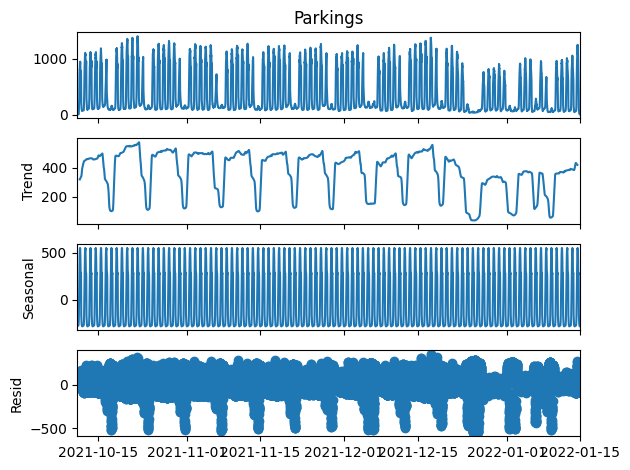

KeyboardInterrupt: 

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.seasonal import seasonal_decompose
from datetime import datetime

# Load the dataset
df = pd.read_csv('../preprocess/parking_time_series_with_features_15min.csv', delimiter=',')

# Parse the 'Time' column to datetime and set it as index
df['Time'] = pd.to_datetime(df['Time'])
df.set_index('Time', inplace=True)
df.sort_index(inplace=True)

# Seasonal decomposition
# Since the data is already in 15-minute intervals, we'll directly decompose it
decomposition = seasonal_decompose(df['Parkings'], model='additive', period=96)  # 96 periods in a day (24 hours * 4 quarters)
decomposition.plot()
plt.show()

# Split the data into training and test sets
end_date = datetime(2022, 1, 1)
train_data = df[df.index < end_date]
test_data = df[df.index >= end_date]

# Ensure the training data index has a frequency set (15 minutes)
train_data.index = pd.DatetimeIndex(train_data.index.values, freq='15min')  # '15T' stands for 15-minute frequency

# Define SARIMA model parameters (p, d, q) and seasonal parameters (P, D, Q, m)
p = 3
d = 1
q = 2
P = 1
D = 1
Q = 1
m = 96  # 96 periods in a day (15 minutes * 96 = 24 hours)

# Fit the SARIMA model
model = SARIMAX(train_data['Parkings'], order=(p, d, q), seasonal_order=(P, D, Q, m))
sarima_results = model.fit()

# Model diagnostics
sarima_results.plot_diagnostics(figsize=(15, 12))
plt.show()

# Predict using the fitted model
predictions = sarima_results.predict(start=test_data.index[0], end=test_data.index[-1], dynamic=False)

# Print the data and predictions
print(train_data)
print(test_data)
print(predictions)

# Plot the actual vs predicted values
plt.figure(figsize=(12, 6))
plt.plot(train_data.index, train_data['Parkings'], label='Train')
plt.plot(test_data.index, test_data['Parkings'], label='Test')
plt.plot(test_data.index, predictions, label='Predicted', color='red')
plt.legend()
plt.show()


In [7]:

from sklearn.metrics import mean_squared_error

# Calculate Mean Squared Error (MSE)
mse = mean_squared_error(test_data['Parkings'], predictions)
print(f'Mean Squared Error (MSE): {mse}')



Mean Squared Error (MSE): 54896.58181341379


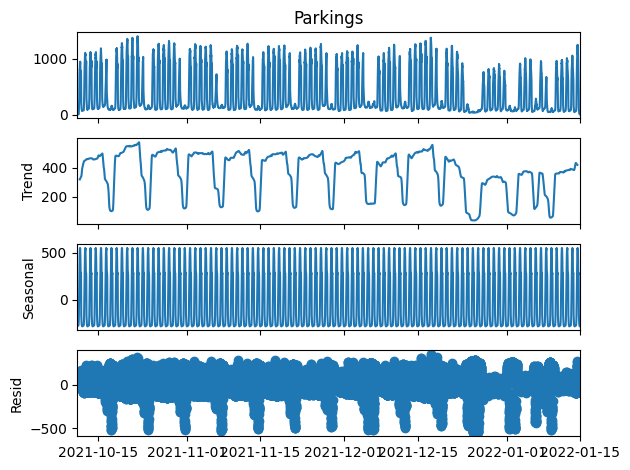

             Parkings  day_of_year   weekday      hour  is_holiday
Parkings     1.000000     0.082201 -0.219631  0.152346   -0.331861
day_of_year  0.082201     1.000000 -0.005760  0.000416   -0.074872
weekday     -0.219631    -0.005760  1.000000 -0.000186    0.578922
hour         0.152346     0.000416 -0.000186  1.000000    0.000090
is_holiday  -0.331861    -0.074872  0.578922  0.000090    1.000000


In [33]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.seasonal import seasonal_decompose
from datetime import datetime

# Load the dataset
df = pd.read_csv('../preprocess/parking_time_series_with_features_15min.csv', delimiter=',')

# Parse the 'Time' column to datetime and set it as index
df['Time'] = pd.to_datetime(df['Time'])
df.set_index('Time', inplace=True)
df.sort_index(inplace=True)

df['day_of_year'] = df['day_of_year'].astype(int)
df['weekday'] = df['weekday'].astype(int)
df['hour'] = df['hour'].astype(int)
df['is_holiday'] = df['is_holiday'].astype(int)

# Seasonal decomposition
# Since the data is already in 15-minute intervals, we'll directly decompose it
decomposition = seasonal_decompose(df['Parkings'], model='additive', period=96)  # 96 periods in a day (24 hours * 4 quarters)
decomposition.plot()
plt.show()

exogenous_features = ["day_of_year","weekday","hour","is_holiday"]

from sklearn.preprocessing import StandardScaler

# Scale the exogenous features
scaler = StandardScaler()
df[exogenous_features] = scaler.fit_transform(df[exogenous_features])

print(df[['Parkings'] + exogenous_features].corr())  # Check correlations between target and exogenous features



# Split the data into training and test sets
end_date = datetime(2022, 1, 1)
train_data = df[df.index < end_date]
test_data = df[df.index >= end_date]
# Ensure the training data index has a frequency set (15 minutes)
train_data.index = pd.DatetimeIndex(train_data.index.values, freq='15min')  # '15T' stands for 15-minute frequency

# Split the exogenous features into train and test sets, aligned with the target variable
exogenous_train = df.loc[df.index < end_date, exogenous_features]
exogenous_test = df.loc[df.index >= end_date, exogenous_features]


# Define SARIMA model parameters (p, d, q) and seasonal parameters (P, D, Q, m)
p = 3
d = 1
q = 2
P = 0
D = 1
Q = 0
m = 96  # 96 periods in a day (15 minutes * 96 = 24 hours)

c:\Users\Viktor\Documents\dipp\parking-prediction\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency 15min will be used.
  self._init_dates(dates, freq)
c:\Users\Viktor\Documents\dipp\parking-prediction\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency 15min will be used.
  self._init_dates(dates, freq)


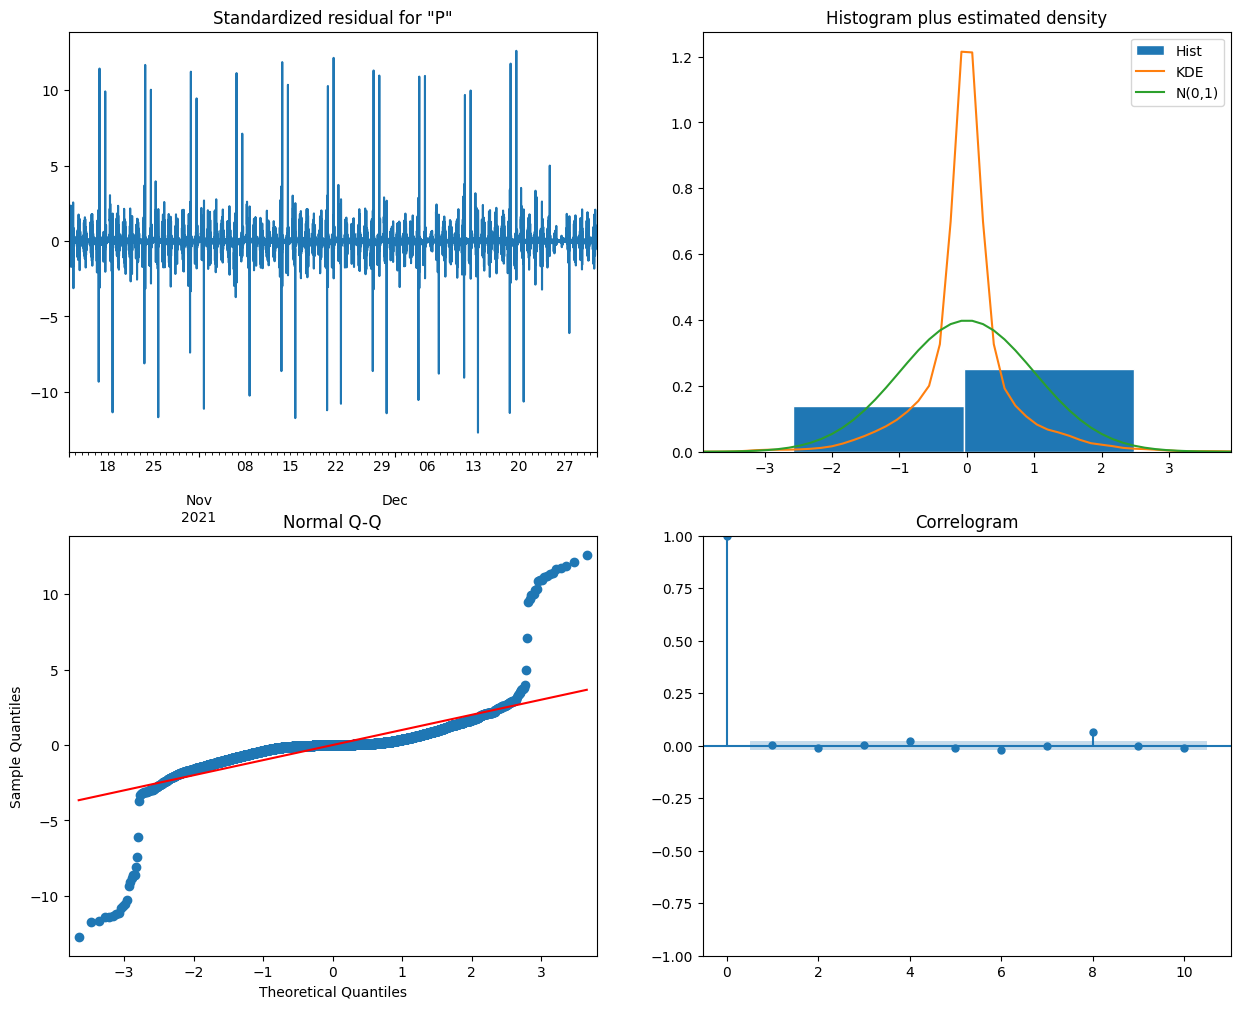

In [34]:

# Fit the SARIMA model
model = SARIMAX(train_data['Parkings'], order=(p, d, q), seasonal_order=(P, D, Q, m), exog=exogenous_train)
sarima_results = model.fit()

# Model diagnostics
sarima_results.plot_diagnostics(figsize=(15, 12))
plt.show()


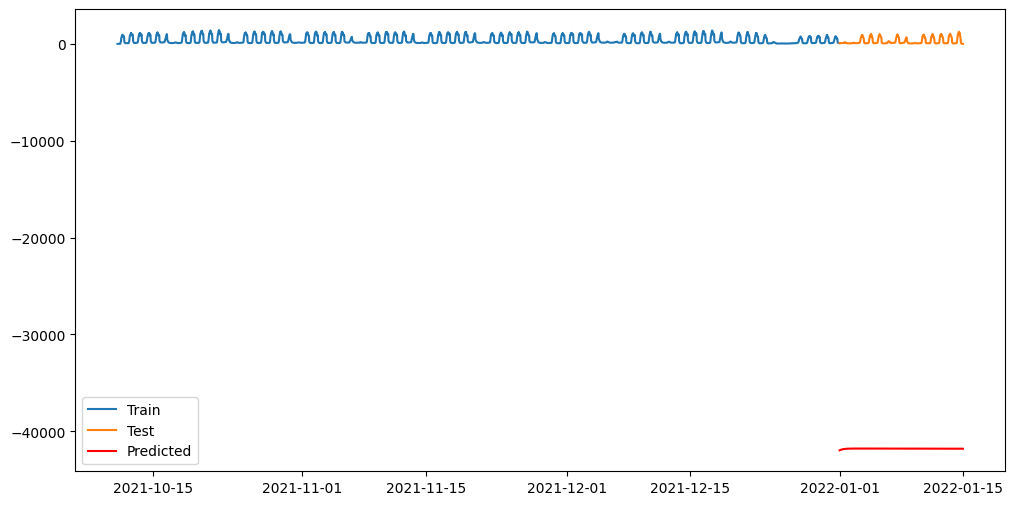

In [27]:
# Make predictions
sarima_pred = sarima_results.predict(start=test_data.index[0], end=test_data.index[-1], exog=exogenous_test)

# Plot the actual vs predicted values
plt.figure(figsize=(12, 6))
plt.plot(train_data.index, train_data['Parkings'], label='Train')
plt.plot(test_data.index, test_data['Parkings'], label='Test')
plt.plot(test_data.index, sarima_pred, label='Predicted', color='red')
plt.legend()
plt.show()